In [1]:
# Locate the project independently of the machine and Jupyter launch directory.
import os as _path_os
import sys as _path_sys
from pathlib import Path as _ProjectPath
_path_start = _ProjectPath(__file__).resolve().parent if '__file__' in globals() else _ProjectPath.cwd()
_path_roots = ([_ProjectPath(_path_os.environ['TRAVELLING_WAVES_ROOT']).expanduser()]
               if _path_os.environ.get('TRAVELLING_WAVES_ROOT') else [])
_path_roots += [_path_start, *_path_start.parents]
_path_root = next((p for p in _path_roots if (p / 'project_locations.py').is_file()), None)
if _path_root is None:
    _path_roots = [p for mount, pattern in [('/Volumes', '*/travelling_waves'),
                    ('/media', '*/*/travelling_waves'), ('/mnt', '*/travelling_waves')]
                   for p in _ProjectPath(mount).glob(pattern)
                   if (p / 'project_locations.py').is_file()]
    if len(_path_roots) != 1:
        raise FileNotFoundError('Cannot uniquely locate travelling_waves. Set TRAVELLING_WAVES_ROOT to its directory.')
    _path_root = _path_roots[0]
_path_sys.path.insert(0, str(_path_root))
from project_locations import project_path, font_path

%matplotlib inline
from pathlib import Path
import sys, importlib
from shutil import copyfile
import pandas as pd
from IPython.display import display

# Start Jupyter within the project; locate the shared path settings.
CODE_DIR = Path(project_path('tw/decoding_gpu'))
sys.path.insert(0, str(CODE_DIR))
BASE = CODE_DIR / "guven/behavior_corr"
sys.path.insert(0, str(BASE / 'fixed_window'))
import guven_tw_fixed_decoding_partial_corr as analysis
importlib.reload(analysis)
from functions.corratlation_funcs import correlation_statistics, tw_decoding_corr_plot_funcs as corr_plots
importlib.reload(correlation_statistics)
importlib.reload(corr_plots)


# Select the decoding version here; save figures only, and display statistics inline.
DECODING_DIR = analysis.DEC
TW_DIR = analysis.TW
TW_WINDOW = (0.75, 1.85)
FREQUENCY_BAND = (8, 12)
SUBJECTS = list(range(1, 31))
SESSIONS = [1, 2, 3, 4]
TARGETS = ('cue', 'uncue', 'cue_minus_uncue')
out = Path(DECODING_DIR) / 'tw_correlation'
FIG_DIR = out / 'figures'
PUBLICATION_FIG_DIR = Path(project_path('tw/result/figs/guven/no-bl'))
out.mkdir(parents=True, exist_ok=True)
parameters = dict(decoding_dir=str(DECODING_DIR), tw_dir=str(TW_DIR),
    tw_centres_target_s=TW_WINDOW, frequency_band_hz=FREQUENCY_BAND,
    fixed_decoding_window_impulse1_s=[.1,.4], fixed_window_interval='(100,400] ms',
    subjects=SUBJECTS, sessions=SESSIONS, lateralization_reference='cued side',
    partial_control='intercept + global trial order, pooled within subject',
    session_aggregation='pool trials; retain session mean differences', group_test='two-sided one-sample t with Bayesian t BF10', p_values='raw; no correction across 6 comparisons per analysis', ci='95% t CI on Fisher z, transformed to r')
print('Output:', out)
def show_group_statistics(table):
    """Print Fisher-z group r and the arithmetic mean r ± SEM used in the plot."""
    report = table.copy()
    report['mean_r ± SEM'] = [f'{mean:.6f} ± {sem:.6f}'
                              for mean, sem in zip(report.mean_r, report.sem_r)]
    columns = ['target', 'measure', 'N', 'r', 'mean_r', 'sem_r',
               'mean_r ± SEM', 't', 'df', 'p_raw', 'BF10']
    display(report[columns])

MEASURES = ('FW_contra_minus_ipsi', 'BW_contra_minus_ipsi')
PANELS = [(target, 'contra_minus_ipsi', corr_plots.DECODING_TITLES[target])
          for target in TARGETS]


Output: /media/dilay/T7/travelling_waves/tw/result/guven_fix_decoding/tw_correlation


In [2]:
trials, audit = analysis.extract(DECODING_DIR, TW_DIR, TW_WINDOW, FREQUENCY_BAND, SUBJECTS, SESSIONS)
display(trials.groupby(['subject','session']).size().unstack())


Subject 01, session 1: 359 matched trials
Subject 01, session 2: 347 matched trials
Subject 01, session 3: 345 matched trials
Subject 01, session 4: 346 matched trials
Subject 02, session 1: 324 matched trials
Subject 02, session 2: 343 matched trials
Subject 02, session 3: 344 matched trials
Subject 02, session 4: 344 matched trials
Subject 03, session 1: 254 matched trials
Subject 03, session 2: 355 matched trials
Subject 03, session 3: 321 matched trials
Subject 03, session 4: 344 matched trials
Subject 04, session 1: 357 matched trials
Subject 04, session 2: 334 matched trials
Subject 04, session 3: 354 matched trials
Subject 04, session 4: 348 matched trials
Subject 05, session 1: 357 matched trials
Subject 05, session 2: 356 matched trials
Subject 05, session 3: 350 matched trials
Subject 05, session 4: 356 matched trials
Subject 06, session 1: 342 matched trials
Subject 06, session 2: 359 matched trials
Subject 06, session 3: 358 matched trials
Subject 06, session 4: 352 matched

session,1,2,3,4
subject,,,,
1,359,347,345,346
2,324,343,344,344
3,254,355,321,344
4,357,334,354,348
5,357,356,350,356
6,342,359,358,352
7,316,300,330,336
8,352,337,352,355
9,351,350,359,321


## partial correlation




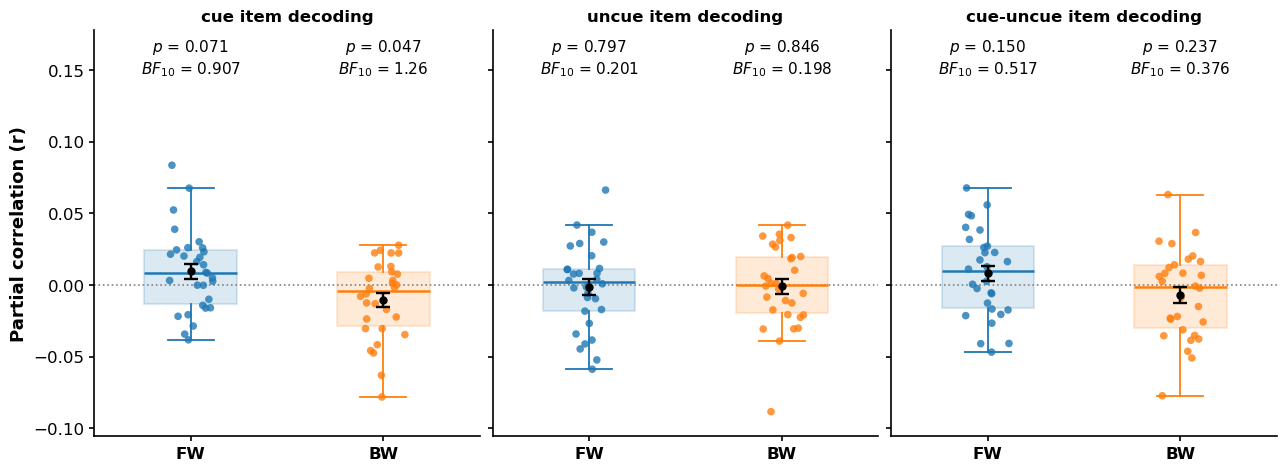

,target,measure,N,r,mean_r,sem_r,mean_r ± SEM,t,df,p_raw,BF10
0,cue,BW_contra_minus_ipsi,30,-0.010266,-0.010255,0.004939,-0.010255 ± 0.004939,-2.076598,29,0.046806,1.261024
1,uncue,BW_contra_minus_ipsi,30,-0.001011,-0.001005,0.005164,-0.001005 ± 0.005164,-0.195629,29,0.846265,0.197893
2,cue_minus_uncue,BW_contra_minus_ipsi,30,-0.006731,-0.006724,0.005569,-0.006724 ± 0.005569,-1.207585,29,0.236964,0.376450
3,cue,FW_contra_minus_ipsi,30,0.009746,0.009734,0.005196,0.009734 ± 0.005196,1.873639,29,0.071090,0.907373
4,uncue,FW_contra_minus_ipsi,30,-0.001392,-0.001390,0.005363,-0.001390 ± 0.005363,-0.259288,29,0.797245,0.200566
5,cue_minus_uncue,FW_contra_minus_ipsi,30,0.008080,0.008073,0.005465,0.008073 ± 0.005465,1.477474,29,0.150328,0.516892


Saved: /media/dilay/T7/travelling_waves/tw/result/guven_fix_decoding/tw_correlation/figures/cue_partial_correlation.png
Saved: /media/dilay/T7/travelling_waves/tw/result/figs/guven/no-bl/cue_partial_correlation.png


In [3]:
results, subject_correlations = analysis.analyze(trials)
subject_correlations = subject_correlations[
    subject_correlations.side == 'contra_minus_ipsi'].copy()
results = results[results.side == 'contra_minus_ipsi'].copy()
all_subjects = subject_correlations.copy()
all_subjects['measure'] = all_subjects.direction + '_' + all_subjects.side
partial_results = corr_plots.plot_correlation_boxes(all_subjects,
    panels=PANELS, out=FIG_DIR, name='cue_partial_correlation', show_r=False)
show_group_statistics(partial_results)
print('Saved:', FIG_DIR / 'cue_partial_correlation.png')

# Export only the partial-correlation figure to the shared TW figure directory.
PUBLICATION_FIG_DIR.mkdir(parents=True, exist_ok=True)
copyfile(FIG_DIR / 'cue_partial_correlation.png',
         PUBLICATION_FIG_DIR / 'cue_partial_correlation.png')
print('Saved:', PUBLICATION_FIG_DIR / 'cue_partial_correlation.png')


## Pearson correlation




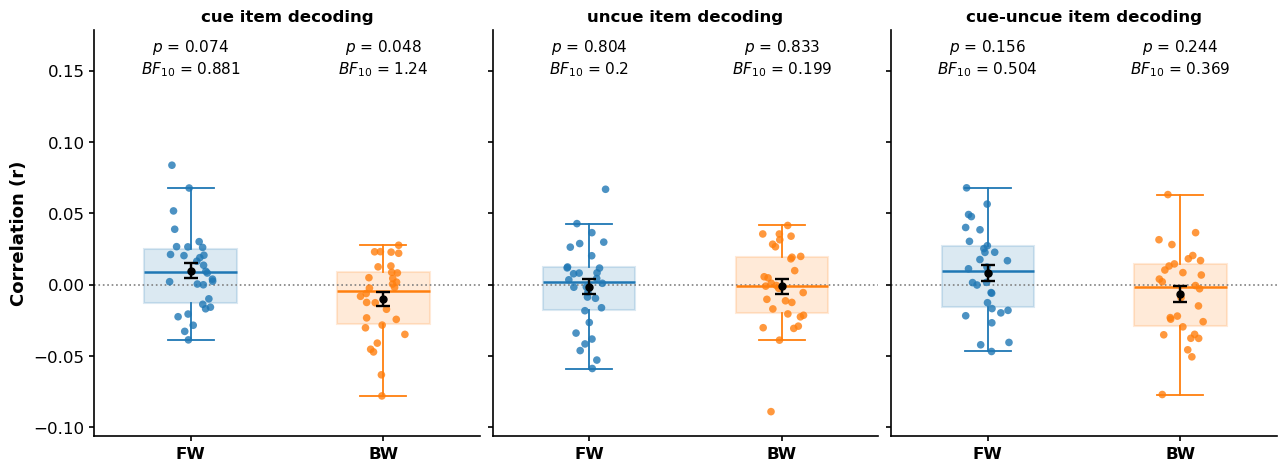

,target,measure,N,r,mean_r,sem_r,mean_r ± SEM,t,df,p_raw,BF10
0,cue,BW_contra_minus_ipsi,30,-0.010187,-0.010176,0.004923,-0.010176 ± 0.004923,-2.067491,29,0.047714,1.241852
1,cue,FW_contra_minus_ipsi,30,0.009628,0.009616,0.005186,0.009616 ± 0.005186,1.854361,29,0.073883,0.880657
2,uncue,BW_contra_minus_ipsi,30,-0.001100,-0.001094,0.005180,-0.001094 ± 0.005180,-0.212209,29,0.833429,0.198514
3,uncue,FW_contra_minus_ipsi,30,-0.001352,-0.001351,0.005389,-0.001351 ± 0.005389,-0.250760,29,0.803768,0.200162
4,cue_minus_uncue,BW_contra_minus_ipsi,30,-0.006606,-0.006600,0.005548,-0.006600 ± 0.005548,-1.189739,29,0.243799,0.369385
5,cue_minus_uncue,FW_contra_minus_ipsi,30,0.007964,0.007957,0.005462,0.007957 ± 0.005462,1.457103,29,0.155832,0.503686


Saved: /media/dilay/T7/travelling_waves/tw/result/guven_fix_decoding/tw_correlation/ordinary_correlation/combined_ordinary_correlation.png


In [4]:
import numpy as np
from scipy import stats

ordinary_out = out / 'ordinary_correlation'
ordinary_out.mkdir(parents=True, exist_ok=True)
ordinary_subject_tables = []
for target in TARGETS:
    rows = []
    for subject, person in trials.groupby('subject'):
        groups = [('pooled', person)]
        for session, table in groups:
            for measure in MEASURES:
                r = stats.pearsonr(table[measure], table['D_' + target]).statistic
                rows.append(dict(subject=subject, session=session, measure=measure,
                    n_trials=len(table), r=r,
                    fisher_z=np.arctanh(np.clip(r, -1+1e-12, 1-1e-12))))
    session_results = pd.DataFrame(rows)
    subjects = session_results.groupby(['subject', 'measure']).agg(
        fisher_z=('fisher_z', 'mean'), n_trials=('n_trials', 'sum')).reset_index()
    subjects['r'] = np.tanh(subjects.fisher_z)
    subjects['target'] = target
    ordinary_subject_tables.append(subjects)
ordinary_all_subjects = pd.concat(ordinary_subject_tables, ignore_index=True)
ordinary_results = corr_plots.plot_correlation_boxes(ordinary_all_subjects,
    panels=PANELS, out=ordinary_out, name='combined_ordinary_correlation',
    ylabel='Correlation (r)', show_r=False)
show_group_statistics(ordinary_results)
print('Saved:', ordinary_out / 'combined_ordinary_correlation.png')
